# Taux de recouvrement Ka / Ks et robustesse au bruit

Ce notebook isole le calcul du taux de recouvrement entre les descripteurs **Ka** et **Ks**
(sur le meme principe que les cellules 38-40 de `lda_kaks.ipynb`, mais restreint a ces deux
descripteurs), puis teste sa robustesse a ~5% de bruit selon deux mecanismes distincts :

- **Option A — bruit gaussien** : perturbation des valeurs brutes de Ka et Ks (N(0, 5%*std))
  *avant* le K-means, puis reclustering complet. Simule une erreur de mesure sur les
  descripteurs.
- **Option B — permutation de labels** : reassignation aleatoire de ~5% des labels de
  cluster deja obtenus, sans reclustering. Plus rapide, sert de test de robustesse a la
  classification plutot qu'au bruit de mesure.

Les deux tournent plusieurs fois (graines differentes) pour obtenir une distribution du
taux de recouvrement sous bruit, comparee a la valeur de reference sans bruit.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

random_state = 42
n_init = 20
N_REPEATS = 20      # nombre de tirages de bruit pour chaque option
NOISE_FRAC = 0.05   # ~5% de bruit

## 1. Chargement et K-means de reference sur Ka et Ks

In [2]:
X_train = pd.read_csv("Données/X_train_clean.csv")
Ka = X_train["Ka"].to_numpy()
Ks = X_train["Ks"].to_numpy()

K_KA = 2
K_KS = 3

print(f"N individus : {len(Ka)}")

N individus : 444


## 2. Fonctions communes : adjacence, recouvrement, K-means

`kmeans_adjacency` standardise puis clusterise une variable 1D et renvoie a la fois les
labels et la matrice d'adjacence (co-appartenance) binaire.
`overlap_stats` calcule S = A1 + A2 et en deduit le taux global et l'indice de Jaccard.

In [3]:
def compute_adjacency(labels):
    """Binary co-membership matrix (N x N) from a label vector.
    Parameters
    ----------
    labels : array-like, shape (N,)
        Cluster labels for each sample.
    Returns
    -------
    adjacency : array, shape (N, N)
        Binary co-membership matrix where adjacency[i, j] = 1 if samples i and j belong to the same cluster, and 0 otherwise.
    """
    Z = pd.get_dummies(labels).astype(int).values
    adjacency = Z @ Z.T
    np.fill_diagonal(adjacency, 0)
    return adjacency


def kmeans_adjacency(values, k, random_state=random_state, n_init=n_init):
    """Standardizes and then clustering a 1D variable; returns (labels, adjacency matrix).
    Parameters
    ----------
    values : array-like, shape (N,)
        The 1D variable to cluster.
    k : int
        The number of clusters.
    random_state : int, optional
        The random state for reproducibility.
    n_init : int, optional
        The number of times the k-means algorithm will be run with different centroid seeds.
    Returns
    -------
    labels : array, shape (N,)
        The cluster labels for each sample.
    adjacency : array, shape (N, N)
        The binary co-membership matrix.
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(np.asarray(values).reshape(-1, 1))
    model = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init="k-means++")
    labels = model.fit_predict(X_scaled)
    return labels, compute_adjacency(labels)


def overlap_stats(A1, A2):
    """Overlay statistics between two adjacency matrices (i-pairs<j only).
    Parameters:
    ----------
    A1 : array-like, shape (N, N)
        First adjacency matrix.
    A2 : array-like, shape (N, N)
        Second adjacency matrix.
    Returns:
        dict with n0/n1/n2 (number of pairs per value of S=A1+A2), total, globaltaux_
        (n2/total) and jaccard (n2/(n2+n1)).
    """
    iu = np.triu_indices_from(A1, k=1)
    s = A1[iu] + A2[iu]
    n0, n1, n2 = int(np.sum(s == 0)), int(np.sum(s == 1)), int(np.sum(s == 2))
    total = len(s)
    return {
        "n0": n0, "n1": n1, "n2": n2, "total": total,
        "taux_global": n2 / total,
        "jaccard": n2 / (n2 + n1) if (n2 + n1) > 0 else np.nan,
    }

## 3. Recouvrement de reference (sans bruit)

In [4]:
labels_Ka, A_Ka = kmeans_adjacency(Ka, k=K_KA)
labels_Ks, A_Ks = kmeans_adjacency(Ks, k=K_KS)

baseline = overlap_stats(A_Ka, A_Ks)

print("Recouvrement Ka / Ks (reference, sans bruit)")
print(f"  Paires en accord (S=2)      : {baseline['n2']:,} ({100*baseline['n2']/baseline['total']:.1f}%)")
print(f"  Paires en desaccord (S=1)   : {baseline['n1']:,} ({100*baseline['n1']/baseline['total']:.1f}%)")
print(f"  Paires separees (S=0)       : {baseline['n0']:,} ({100*baseline['n0']/baseline['total']:.1f}%)")
print(f"  Total paires (S=0+1+2)      : {baseline['total']:,}")
print(f"  Taux global (n2/total)      : {baseline['taux_global']:.3f}")
print(f"  Indice de Jaccard           : {baseline['jaccard']:.3f}")

Recouvrement Ka / Ks (reference, sans bruit)
  Paires en accord (S=2)      : 29,483 (30.0%)
  Paires en desaccord (S=1)   : 38,753 (39.4%)
  Paires separees (S=0)       : 30,110 (30.6%)
  Total paires (S=0+1+2)      : 98,346
  Taux global (n2/total)      : 0.300
  Indice de Jaccard           : 0.432


## 4. Visualisation de la matrice de recouvrement

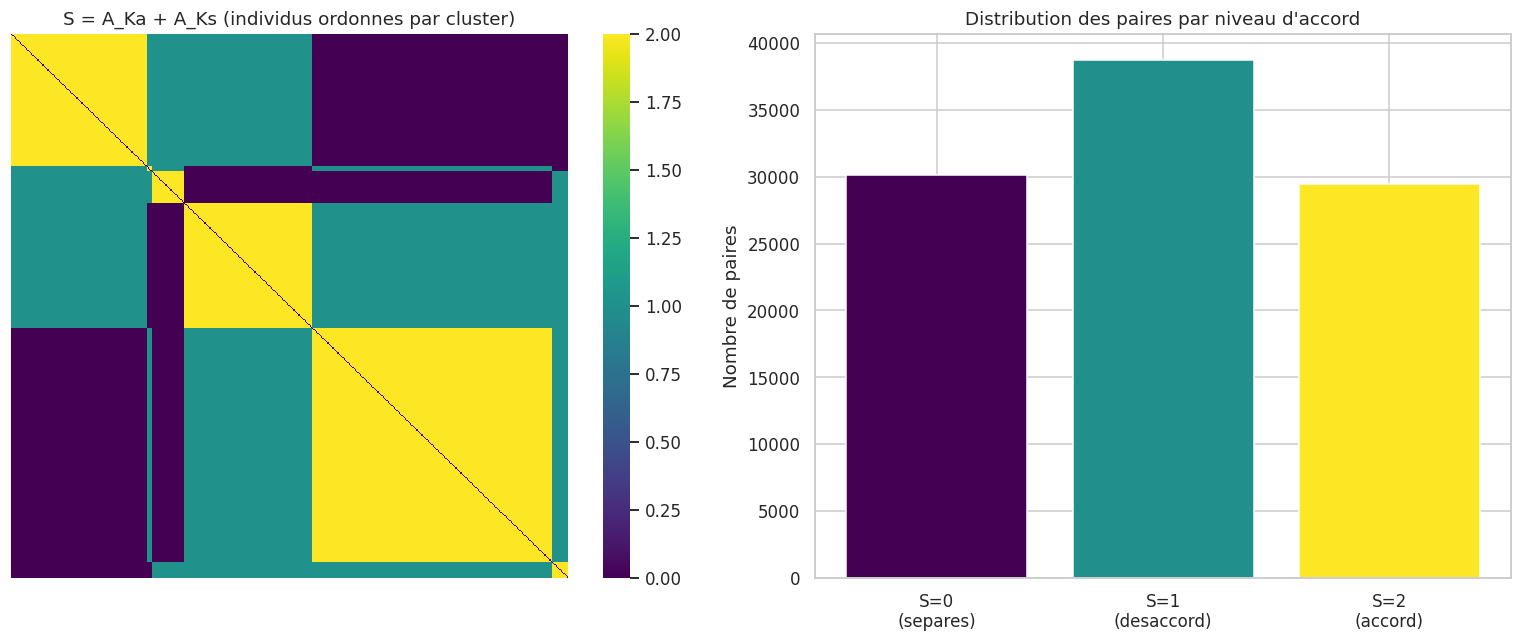

In [5]:
S = A_Ka + A_Ks
order = np.lexsort((labels_Ks, labels_Ka))
S_ordered = S[np.ix_(order, order)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(S_ordered, ax=axes[0], cmap="viridis", cbar=True,
            xticklabels=False, yticklabels=False)
axes[0].set_title("S = A_Ka + A_Ks (individus ordonnes par cluster)")

axes[1].bar(["S=0\n(separes)", "S=1\n(desaccord)", "S=2\n(accord)"],
            [baseline["n0"], baseline["n1"], baseline["n2"]],
            color=["#440154", "#21908C", "#FDE725"])
axes[1].set_ylabel("Nombre de paires")
axes[1].set_title("Distribution des paires par niveau d'accord")

plt.tight_layout()
plt.show()

## 5. Option A — bruit gaussien sur les valeurs brutes (avant K-means)

On ajoute `N(0, NOISE_FRAC * ecart-type)` aux valeurs brutes de Ka et Ks, puis on
reclusterise entierement (nouveau K-means) avant de recalculer le recouvrement. Repete
`N_REPEATS` fois avec des graines differentes.

In [6]:
def gaussian_noise_recluster(values, k, sigma_frac=NOISE_FRAC, seed=0,
                              random_state=random_state, n_init=n_init):
    """Ajoute un bruit gaussien aux valeurs brutes puis reclusterise.
    Paramètres
    ----------
    values : array-like
        Les valeurs brutes.
    k : int
        Le nombre de clusters.
    sigma_frac : float, optional
        Le facteur de bruit gaussien (par défaut NOISE_FRAC).
    seed : int, optional
        La graine pour la génération de nombres aléatoires (par défaut 0).
    random_state : int or RandomState, optional
        L'état aléatoire pour la génération de nombres aléatoires (par défaut None).
    n_init : int, optional
        Le nombre d'initialisations pour K-means (par défaut 10).
    Returns
    -------
    labels : array, shape (N,)
        Les étiquettes de cluster pour chaque échantillon après reclustering.
    adjacency : array, shape (N, N)
        La matrice d'adjacence binaire après reclustering."""
    rng = np.random.default_rng(seed)
    sigma = sigma_frac * np.std(values)
    noisy_values = np.asarray(values) + rng.normal(0, sigma, size=len(values))
    return kmeans_adjacency(noisy_values, k, random_state=random_state, n_init=n_init)


results_A = []
for i in range(N_REPEATS):
    _, A_Ka_noisy_gauss = gaussian_noise_recluster(Ka, k=K_KA, seed=i)
    _, A_Ks_noisy_gauss = gaussian_noise_recluster(Ks, k=K_KS, seed=1000 + i)
    results_A.append(overlap_stats(A_Ka_noisy_gauss, A_Ks_noisy_gauss))

df_A = pd.DataFrame(results_A)
print("Option A - bruit gaussien (N_REPEATS =", N_REPEATS, ")")
print(f"  Taux global : moyenne={df_A['taux_global'].mean():.3f}  ecart-type={df_A['taux_global'].std():.3f}")
print(f"  Jaccard     : moyenne={df_A['jaccard'].mean():.3f}  ecart-type={df_A['jaccard'].std():.3f}")

Option A - bruit gaussien (N_REPEATS = 20 )
  Taux global : moyenne=0.299  ecart-type=0.005
  Jaccard     : moyenne=0.430  ecart-type=0.008


## 6. Option B — permutation de labels (sans reclustering)

On part des labels de cluster deja obtenus (`labels_Ka`, `labels_Ks`) et on en reassigne
aleatoirement ~`NOISE_FRAC` a un autre cluster, sans toucher aux valeurs brutes ni
relancer K-means.

In [7]:
def permute_labels(labels, frac=NOISE_FRAC, seed=0):
    """Reassigne aleatoirement une fraction des labels de cluster a un autre cluster.
    Paramètres
    ----------
    labels : array-like
        Les étiquettes de cluster.
    frac : float, optional
        La fraction des labels à permuter (par défaut NOISE_FRAC).
    seed : int, optional
        La graine pour la génération de nombres aléatoires (par défaut 0).
    Returns
    -------
    labels : array, shape (N,)
        Les étiquettes de cluster permutées."""
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels).copy()
    n = len(labels)
    n_perm = int(round(frac * n))
    idx = rng.choice(n, size=n_perm, replace=False)
    unique_labels = np.unique(labels)
    for i in idx:
        choices = unique_labels[unique_labels != labels[i]]
        if len(choices) > 0:
            labels[i] = rng.choice(choices)
    return labels


results_B = []
for i in range(N_REPEATS):
    labels_Ka_noisy = permute_labels(labels_Ka, seed=i)
    labels_Ks_noisy = permute_labels(labels_Ks, seed=1000 + i)
    A_Ka_permut = compute_adjacency(labels_Ka_noisy)
    A_Ks_permut = compute_adjacency(labels_Ks_noisy)
    results_B.append(overlap_stats(A_Ka_permut, A_Ks_permut))

df_B = pd.DataFrame(results_B)
print("Option B - permutation de labels (N_REPEATS =", N_REPEATS, ")")
print(f"  Paires en accord (S=2)      : {df_B['n2'].sum()/N_REPEATS:,} ({100*df_B['n2'].sum()/df_B['total'].sum():.1f}%)")
print(f"  Paires en desaccord (S=1)   : {df_B['n1'].sum()/N_REPEATS:,} ({100*df_B['n1'].sum()/df_B['total'].sum():.1f}%)")
print(f"  Paires separees (S=0)       : {df_B['n0'].sum()/N_REPEATS:,} ({100*df_B['n0'].sum()/df_B['total'].sum():.1f}%)")
print(f"  Taux global : moyenne={df_B['taux_global'].mean():.3f}  ecart-type={df_B['taux_global'].std():.3f}")
print(f"  Jaccard     : moyenne={df_B['jaccard'].mean():.3f}  ecart-type={df_B['jaccard'].std():.3f}")

Option B - permutation de labels (N_REPEATS = 20 )
  Paires en accord (S=2)      : 26,628.5 (27.1%)
  Paires en desaccord (S=1)   : 42,084.05 (42.8%)
  Paires separees (S=0)       : 29,633.45 (30.1%)
  Taux global : moyenne=0.271  ecart-type=0.006
  Jaccard     : moyenne=0.388  ecart-type=0.010


## 7. Comparaison reference vs. Option A vs. Option B

Boxplots du taux global et du Jaccard sous les deux mecanismes de bruit, avec la valeur de
reference (sans bruit) tracee en repere. Un ecart faible entre la reference et une option
indique un recouvrement robuste a ce type de bruit ; l'option B, plus agressive
(reassignation directe des labels), donnera generalement un ecart plus marque que
l'option A a NOISE_FRAC egal.

/tmp/ipykernel_6327/4180629680.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(box_data_taux, labels=["Option A\n(gaussien)", "Option B\n(permutation)"])
/tmp/ipykernel_6327/4180629680.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(box_data_jaccard, labels=["Option A\n(gaussien)", "Option B\n(permutation)"])


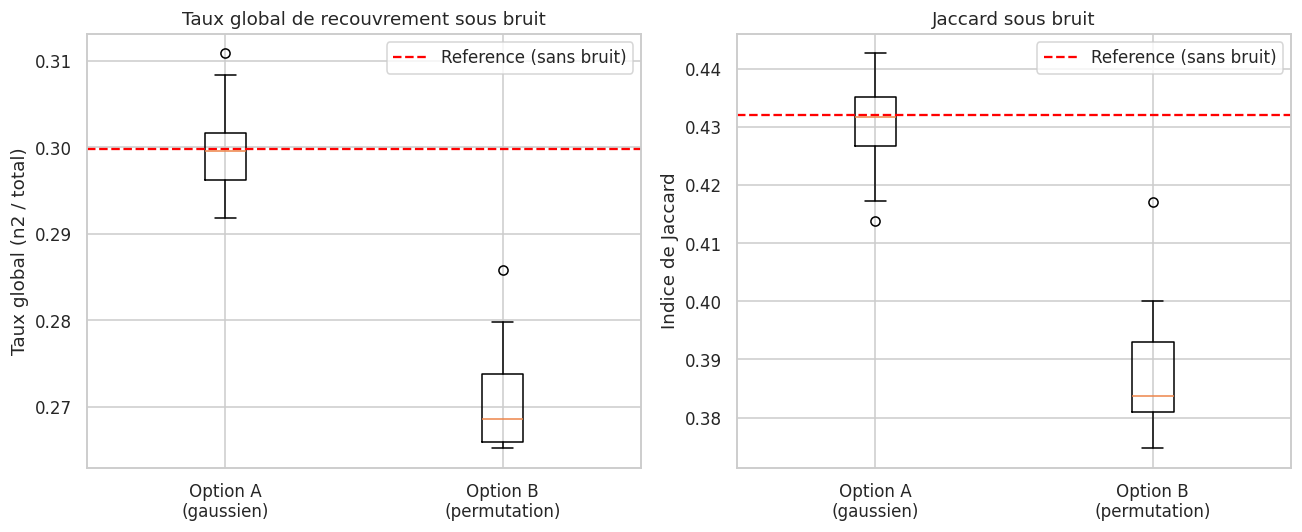

,taux_global,jaccard
reference,0.299789,0.432074
option_A_gaussien_moyenne,0.299430,0.430337
option_A_gaussien_ecart_type,0.004835,0.007910
option_B_permutation_moyenne,0.270763,0.387597
option_B_permutation_ecart_type,0.005696,0.010344


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

box_data_taux = [df_A["taux_global"], df_B["taux_global"]]
axes[0].boxplot(box_data_taux, labels=["Option A\n(gaussien)", "Option B\n(permutation)"])
axes[0].axhline(baseline["taux_global"], color="red", linestyle="--", label="Reference (sans bruit)")
axes[0].set_ylabel("Taux global (n2 / total)")
axes[0].set_title("Taux global de recouvrement sous bruit")
axes[0].legend()

box_data_jaccard = [df_A["jaccard"], df_B["jaccard"]]
axes[1].boxplot(box_data_jaccard, labels=["Option A\n(gaussien)", "Option B\n(permutation)"])
axes[1].axhline(baseline["jaccard"], color="red", linestyle="--", label="Reference (sans bruit)")
axes[1].set_ylabel("Indice de Jaccard")
axes[1].set_title("Jaccard sous bruit")
axes[1].legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "reference": {"taux_global": baseline["taux_global"], "jaccard": baseline["jaccard"]},
    "option_A_gaussien_moyenne": {"taux_global": df_A["taux_global"].mean(), "jaccard": df_A["jaccard"].mean()},
    "option_A_gaussien_ecart_type": {"taux_global": df_A["taux_global"].std(), "jaccard": df_A["jaccard"].std()},
    "option_B_permutation_moyenne": {"taux_global": df_B["taux_global"].mean(), "jaccard": df_B["jaccard"].mean()},
    "option_B_permutation_ecart_type": {"taux_global": df_B["taux_global"].std(), "jaccard": df_B["jaccard"].std()},
}).T
summary

In [9]:
# Récuperer matrice d'adjacence de référence et de permutation pour les sauvegarder dans un fichier CSV
A_Ka_df = pd.DataFrame(A_Ka)
A_Ks_df = pd.DataFrame(A_Ks)
A_Ka_df.to_csv("Données/adjacency/recouvrement/A_Ka_ref.csv", index=False)
A_Ks_df.to_csv("Données/adjacency/recouvrement/A_Ks_ref.csv", index=False)

A_Ka_permut_df = pd.DataFrame(A_Ka_permut)
A_Ks_permut_df = pd.DataFrame(A_Ks_permut)
A_Ka_permut_df.to_csv("Données/adjacency/recouvrement/A_Ka_permut.csv", index=False)
A_Ks_permut_df.to_csv("Données/adjacency/recouvrement/A_Ks_permut.csv", index=False)

## Pipeline mimiSBM

### Configuration

In [10]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
from scipy.special import entr

from mimisbm_main.mimisbm._base import MimiSBM


# Configuration
BASE_DIR = Path("Données/adjacency/recouvrement")
OUTPUT_DIR = Path("Plots/mimiSBM/KaKs_permutation_5pct")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MATRIX_PATHS = {
    "Ka": BASE_DIR / "A_Ka_ref.csv",
    "Ks": BASE_DIR / "A_Ks_ref.csv",
}

K_VALUES = range(2, 11)
Q_VALUES = range(1, 5)
N_INIT = 10
PRIORS = "jeffreys"
MAX_ITER = 100
TOL = 1e-6
BASE_SEED = 0
PERMUTATION_SEED = 5
PERMUTATION_RATE = 0.05

### Assemblage tenseur et matrices d'adjacences

In [11]:
def load_adjacency_matrices(paths):
    matrices = {}
    for name, path in paths.items():
        matrix = pd.read_csv(path).to_numpy()

        if not np.all(np.isin(np.unique(matrix), [0, 1])):
            raise ValueError(f"{name}: la matrice contient des valeurs hors de {{0, 1}}.")
        if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
            raise ValueError(f"{name}: la matrice doit etre carree.")

        matrix = matrix.astype(np.int64)
        np.fill_diagonal(matrix, 0)
        matrix = np.maximum(matrix, matrix.T)
        matrices[name] = matrix

    shapes = {matrix.shape for matrix in matrices.values()}
    if len(shapes) != 1:
        raise ValueError(f"Tailles de matrices incompatibles: {shapes}")

    return matrices


def build_tensor(matrices):
    names = list(matrices)
    tensor = np.stack([matrices[name] for name in names], axis=2)
    return tensor, names


def permute_adjacency_labels(adjacency, rate, rng):
    """Reaffecte aleatoirement rate des individus a un autre cluster."""
    adjacency = np.maximum(adjacency, adjacency.T).astype(bool)
    same_cluster = adjacency.copy()
    np.fill_diagonal(same_cluster, True)

    # Les lignes identiques identifient les clusters, y compris les singletons.
    _, labels = np.unique(same_cluster, axis=0, return_inverse=True)
    clusters = np.unique(labels)

    if len(clusters) < 2:
        raise ValueError("Il faut au moins deux clusters pour permuter les labels.")

    n_changed = round(rate * len(labels))
    selected = rng.choice(len(labels), size=n_changed, replace=False)

    for index in selected:
        alternatives = clusters[clusters != labels[index]]
        labels[index] = rng.choice(alternatives)

    permuted = (labels[:, None] == labels[None, :]).astype(np.int64)
    np.fill_diagonal(permuted, 0)
    return permuted

### Fonctions modèles et critères

In [12]:
def fit_best_of_n_init(tensor, k, q):
    best_model = None
    best_elbo = -np.inf
    best_seed = None

    for run in range(N_INIT):
        seed = BASE_SEED + run
        model = MimiSBM(
            n_clusters=k,
            n_components=q,
            clusters_prior=PRIORS,
            components_prior=PRIORS,
            adjacency_prior=PRIORS,
            max_iter=MAX_ITER,
            tol=TOL,
            random_state=seed,
        )
        model.fit(tensor)

        if model.elbo_ > best_elbo:
            best_model = model
            best_elbo = model.elbo_
            best_seed = seed

    return best_model, best_seed


def approximate_icl(model, n, n_views):
    k, q = model.n_clusters, model.n_components
    penalty = (
        0.5 * (k * (k + 1) / 2 * q) * np.log(n_views * n * (n - 1) / 2)
        + 0.5 * (k - 1) * np.log(n)
        + 0.5 * (q - 1) * np.log(n_views)
    )
    return model.elbo_ - penalty


def grid_search(tensor):
    n, _, n_views = tensor.shape
    results = []
    bests = {
        criterion: {"score": -np.inf, "model": None, "K": None, "Q": None}
        for criterion in ("ILVB", "ICL_variationnel", "ICL_approx")
    }

    for k in K_VALUES:
        for q in Q_VALUES:
            model, seed = fit_best_of_n_init(tensor, k, q)

            ilvb = model.elbo_
            icl_variationnel = ilvb - (
                entr(model.cluster_responsibilities_).sum()
                + entr(model.component_responsibilities_).sum()
            )
            icl_approx = approximate_icl(model, n, n_views)

            scores = {
                "ILVB": ilvb,
                "ICL_variationnel": icl_variationnel,
                "ICL_approx": icl_approx,
            }
            results.append({
                "K": k,
                "Q": q,
                **scores,
                "converged": model.converged_,
                "best_seed": seed,
            })

            for criterion, score in scores.items():
                if score > bests[criterion]["score"]:
                    bests[criterion] = {
                        "score": score,
                        "model": model,
                        "K": k,
                        "Q": q,
                    }

    return pd.DataFrame(results), bests

### Lancement avec 2 tenseurs un pour les normal et un pour les permutés

In [13]:
# Matrices originales et matrices avec 5 % des labels reassigned
original_matrices = load_adjacency_matrices(MATRIX_PATHS)
original_tensor, view_names = build_tensor(original_matrices)

rng = np.random.default_rng(PERMUTATION_SEED)
permuted_matrices = {
    name: permute_adjacency_labels(matrix, PERMUTATION_RATE, rng)
    for name, matrix in original_matrices.items()
}
permuted_tensor, _ = build_tensor(permuted_matrices)

# Ajustement mimiSBM separe sur les donnees originales et permutees
results_by_scenario = {}
bests_by_scenario = {}

for scenario, tensor in {
    "original": original_tensor,
    "permute_5pct": permuted_tensor,
}.items():
    print(f"\nAjustement mimiSBM : {scenario}")
    results_by_scenario[scenario], bests_by_scenario[scenario] = grid_search(tensor)

# Comparaison des meilleurs modeles selon chaque critere
summary = pd.DataFrame([
    {
        "scenario": scenario,
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for scenario, bests in bests_by_scenario.items()
    for criterion, best in bests.items()
])

display(summary)

# Sauvegarde des resultats et des meilleurs modeles
all_results = pd.concat(
    [df.assign(scenario=scenario) for scenario, df in results_by_scenario.items()],
    ignore_index=True,
)
all_results.to_csv(OUTPUT_DIR / "grid_search_results.csv", index=False)
summary.to_csv(OUTPUT_DIR / "best_models_summary.csv", index=False)

with open(OUTPUT_DIR / "best_models.pkl", "wb") as file:
    pickle.dump(bests_by_scenario, file)

print(f"\nResultats sauvegardes dans : {OUTPUT_DIR}")


Ajustement mimiSBM : original

Ajustement mimiSBM : permute_5pct


,scenario,critere,K,Q,score
0,original,ILVB,6,2,-789.718971
1,original,ICL_variationnel,6,2,-789.718971
2,original,ICL_approx,6,2,-1061.282387
3,permute_5pct,ILVB,6,2,-854.587579
4,permute_5pct,ICL_variationnel,6,2,-854.587579
5,permute_5pct,ICL_approx,6,2,-1126.150995



Resultats sauvegardes dans : Plots/mimiSBM/KaKs_permutation_5pct


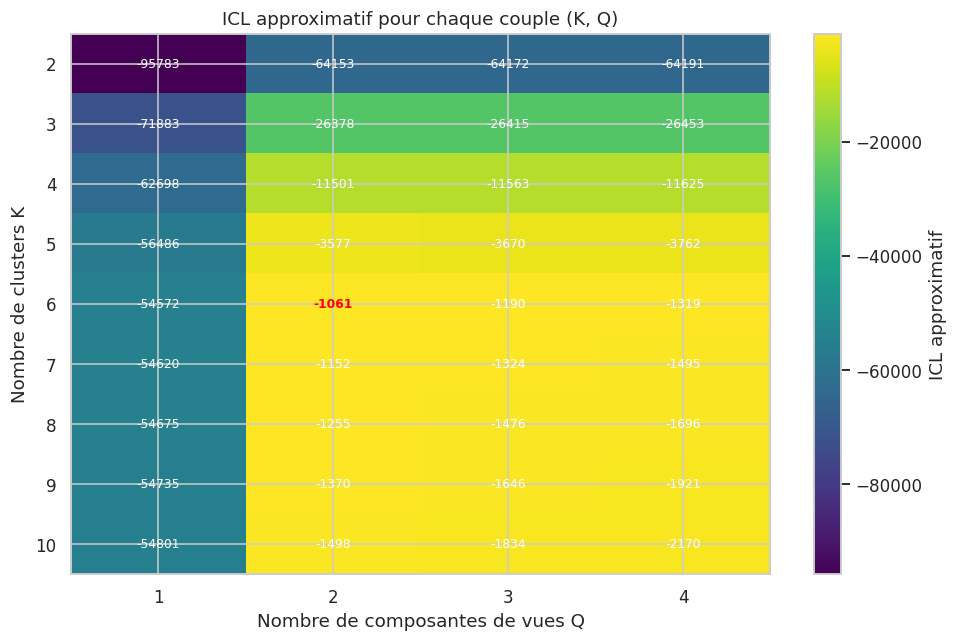

In [14]:
icl_matrix = results_by_scenario["original"].pivot(
    index="K",
    columns="Q",
    values="ICL_approx",
)

plt.figure(figsize=(9, 6))
plt.imshow(icl_matrix.values, aspect="auto", cmap="viridis")

plt.xticks(range(len(icl_matrix.columns)), icl_matrix.columns)
plt.yticks(range(len(icl_matrix.index)), icl_matrix.index)
plt.xlabel("Nombre de composantes de vues Q")
plt.ylabel("Nombre de clusters K")
plt.title("ICL approximatif pour chaque couple (K, Q)")

icl_values = icl_matrix.to_numpy()
max_i, max_j = np.unravel_index(np.nanargmax(icl_values), icl_values.shape)

for i in range(icl_matrix.shape[0]):
    for j in range(icl_matrix.shape[1]):
        is_max = (i == max_i and j == max_j)
        plt.text(
            j,
            i,
            f"{icl_matrix.iloc[i, j]:.0f}",
            ha="center",
            va="center",
            color="red" if is_max else "white",
            fontweight="bold" if is_max else "normal",
            fontsize=8,
        )

plt.colorbar(label="ICL approximatif")
plt.tight_layout()
plt.show()

### Lancement avec les 4 descripteurs (2 normaux et 2 permutés) pour un tenseur

In [15]:
# Charger les matrices originales
original_matrices = load_adjacency_matrices(MATRIX_PATHS)

# Creer les versions permutees avec 5 % des labels reassigned
rng = np.random.default_rng(PERMUTATION_SEED)
permuted_matrices = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        rng,
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices["Ka"],
    "Ks_permuted": permuted_matrices["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)

print(f"Tenseur mimiSBM : shape={mixed_tensor.shape}")
print(f"Ordre des vues : {mixed_view_names}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df, mixed_bests = grid_search(mixed_tensor)

# Resume du meilleur modele selon chaque critere
summary = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests.items()
])

display(summary)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,10,4,-20223.774698
1,ICL_variationnel,10,4,-20223.774698
2,ICL_approx,10,4,-21670.364917


### Visualisation itérations modèles

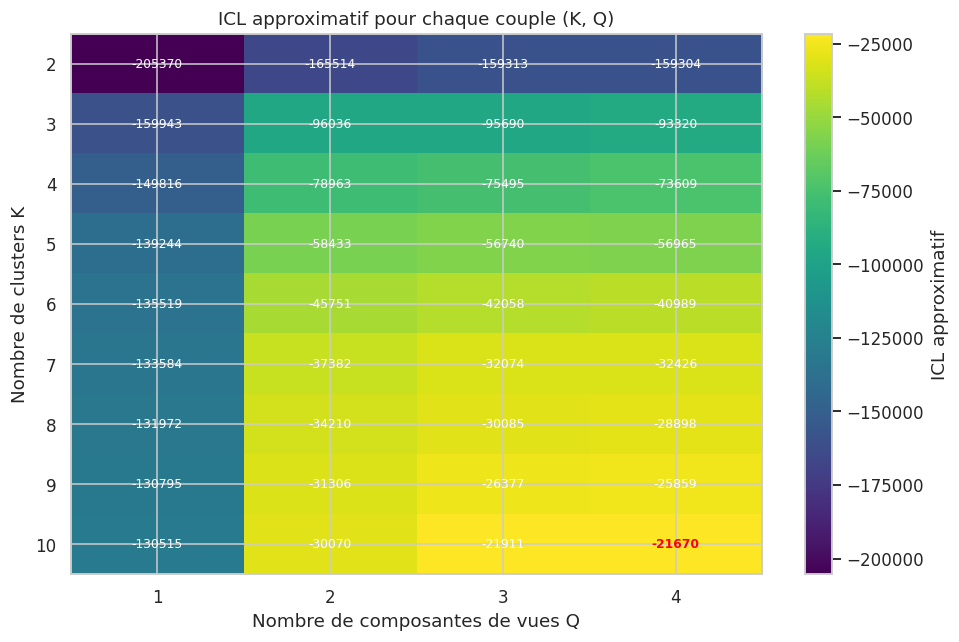

In [16]:
icl_matrix = mixed_results_df.pivot(
    index="K",
    columns="Q",
    values="ICL_approx",
)

plt.figure(figsize=(9, 6))
plt.imshow(icl_matrix.values, aspect="auto", cmap="viridis")

plt.xticks(range(len(icl_matrix.columns)), icl_matrix.columns)
plt.yticks(range(len(icl_matrix.index)), icl_matrix.index)
plt.xlabel("Nombre de composantes de vues Q")
plt.ylabel("Nombre de clusters K")
plt.title("ICL approximatif pour chaque couple (K, Q)")

icl_values = icl_matrix.to_numpy()
max_i, max_j = np.unravel_index(np.nanargmax(icl_values), icl_values.shape)

for i in range(icl_matrix.shape[0]):
    for j in range(icl_matrix.shape[1]):
        is_max = (i == max_i and j == max_j)
        plt.text(
            j,
            i,
            f"{icl_matrix.iloc[i, j]:.0f}",
            ha="center",
            va="center",
            color="red" if is_max else "white",
            fontweight="bold" if is_max else "normal",
            fontsize=8,
        )

plt.colorbar(label="ICL approximatif")
plt.tight_layout()
plt.show()

### Lancement avec 4 descripteurs mais 2 qui sont pareil

In [17]:
# Charger les matrices originales
original_matrices = load_adjacency_matrices(MATRIX_PATHS)

# Creer les versions permutees avec 5 % des labels reassigned
rng = np.random.default_rng(PERMUTATION_SEED)
permuted_matrices = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        rng,
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": original_matrices["Ka"],
    "Ks_permuted": original_matrices["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor, mixed_view_names = build_tensor(mixed_matrices)

print(f"Tenseur mimiSBM : shape={mixed_tensor.shape}")
print(f"Ordre des vues : {mixed_view_names}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df, mixed_bests = grid_search(mixed_tensor)

# Resume du meilleur modele selon chaque critere
summary = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests.items()
])

display(summary)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,6,2,-805.921098
1,ICL_variationnel,6,2,-805.921098
2,ICL_approx,6,2,-1092.387178


### Comparaison avec matrices bruitées à 3%

In [18]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS)
PERMUTATION_RATE = 0.03  # 3% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_3pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_3pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_3pct["Ka"],
    "Ks_permuted": permuted_matrices_3pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_3pct, mixed_view_names_3pct = build_tensor(mixed_matrices_3pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_3pct.shape}")
print(f"Ordre des vues : {mixed_view_names_3pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_3pct, mixed_bests_3pct = grid_search(mixed_tensor_3pct)

# Resume du meilleur modele selon chaque critere
summary_3pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_3pct.items()
])

display(summary_3pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,8,3,-8035.058365
1,ICL_variationnel,8,3,-8035.058365
2,ICL_approx,8,3,-8753.437287


In [19]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_3pct = mixed_bests_3pct["ICL_approx"]["model"]
node_clusters_3pct, view_components_3pct = best_model_3pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_3pct['ICL_approx']['K']}, {mixed_bests_3pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_3pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_3pct,
        "composante": view_components_3pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (8, 3)

Tailles des clusters d'individus (K):
0    186
1    105
2    101
3     22
4      6
5     13
6      4
7      7
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           1
1  Ks_original           0
2  Ka_permuted           2
3  Ks_permuted           0


### Comparaison avec matrices bruitées à 2 %

In [20]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS)
PERMUTATION_RATE = 0.02  # 2% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_2pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_2pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_2pct["Ka"],
    "Ks_permuted": permuted_matrices_2pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_2pct, mixed_view_names_2pct = build_tensor(mixed_matrices_2pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_2pct.shape}")
print(f"Ordre des vues : {mixed_view_names_2pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_2pct, mixed_bests_2pct = grid_search(mixed_tensor_2pct)

# Resume du meilleur modele selon chaque critere
summary_2pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_2pct.items()
])

display(summary_2pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,9,4,-4447.394004
1,ICL_variationnel,9,4,-4447.394004
2,ICL_approx,9,4,-5633.285480


In [21]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_2pct = mixed_bests_2pct["ICL_approx"]["model"]
node_clusters_2pct, view_components_2pct = best_model_2pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_2pct['ICL_approx']['K']}, {mixed_bests_2pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_2pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_2pct,
        "composante": view_components_2pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (9, 4)

Tailles des clusters d'individus (K):
0    186
1    107
2    101
3     24
4      6
5     13
7      4
8      3
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           0
1  Ks_original           1
2  Ka_permuted           2
3  Ks_permuted           3


### Comparaison avec matrices bruitées à 1 %

In [22]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS)
PERMUTATION_RATE = 0.01  # 1% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_1pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_1pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_1pct["Ka"],
    "Ks_permuted": permuted_matrices_1pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_1pct, mixed_view_names_1pct = build_tensor(mixed_matrices_1pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_1pct.shape}")
print(f"Ordre des vues : {mixed_view_names_1pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_1pct, mixed_bests_1pct = grid_search(mixed_tensor_1pct)

# Resume du meilleur modele selon chaque critere
summary_1pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_1pct.items()
])

display(summary_1pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,9,4,-2665.266762
1,ICL_variationnel,9,4,-2665.266762
2,ICL_approx,7,4,-3813.242362


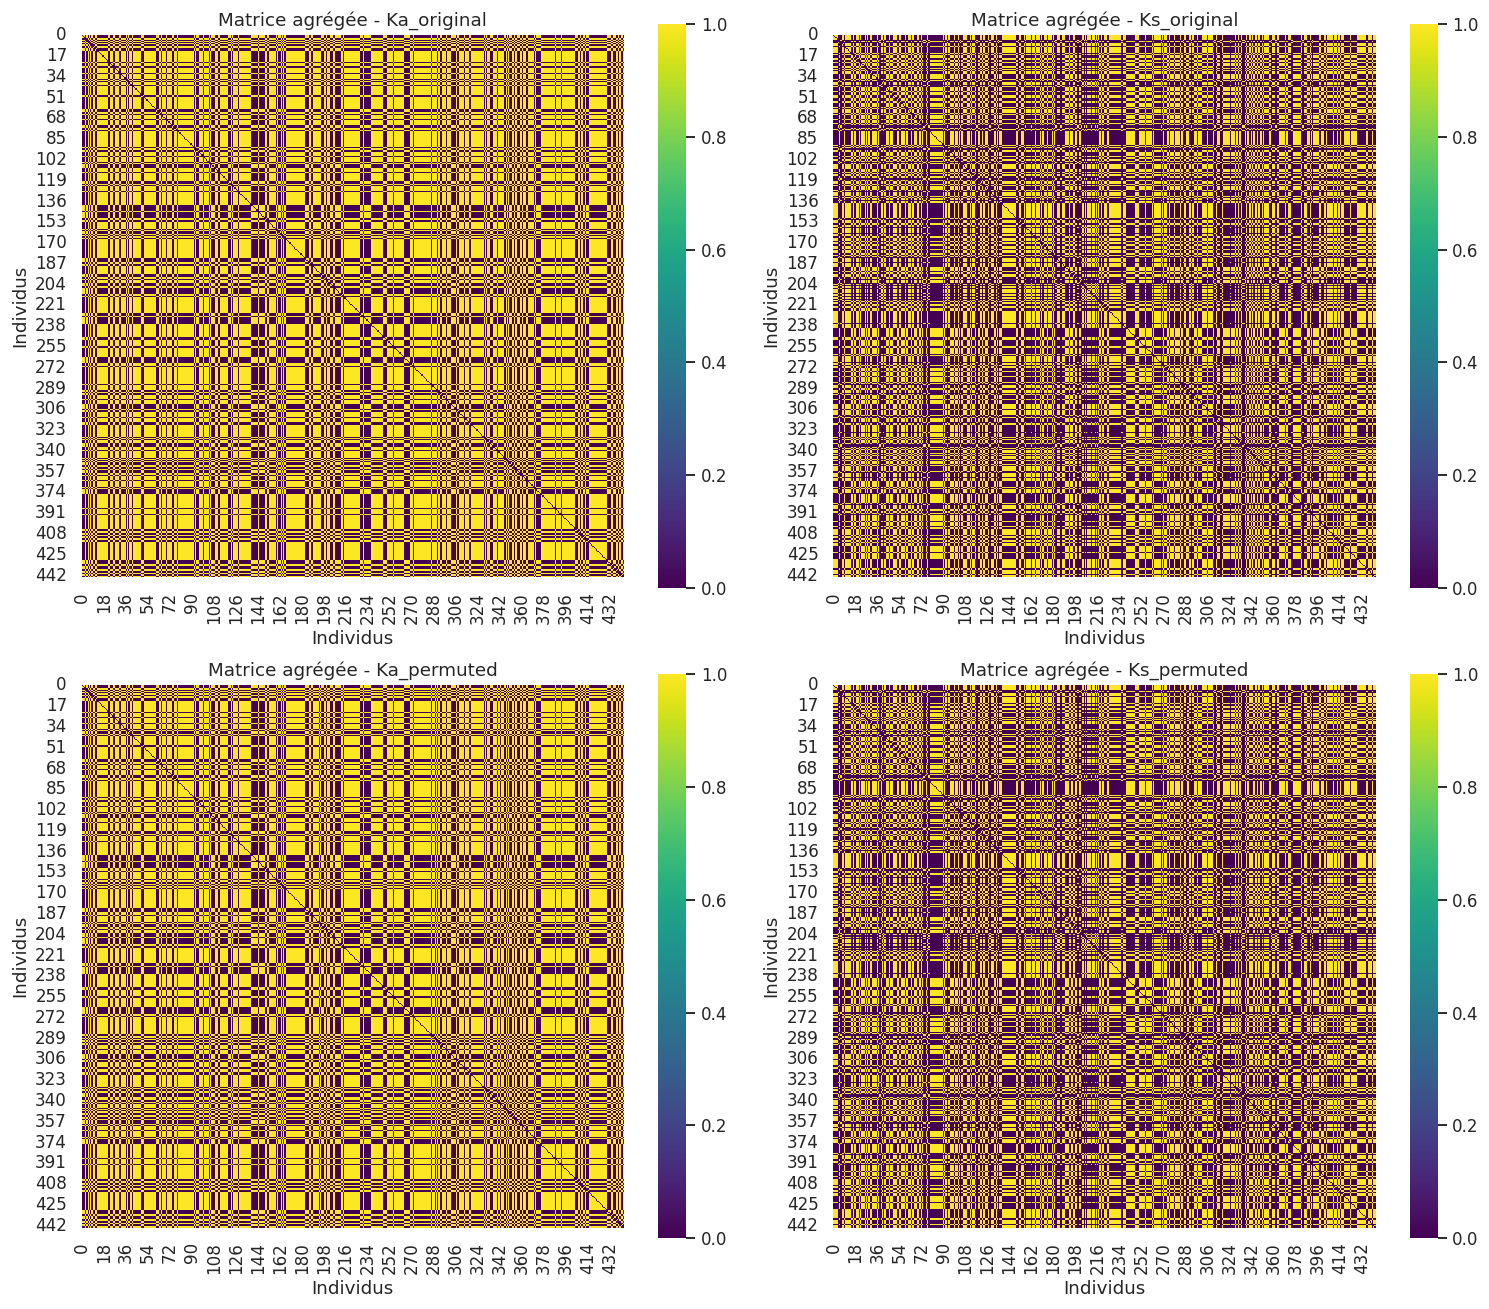

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (family_name, matrix) in zip(axes, mixed_matrices_1pct.items()):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

# Masque les axes inutilisés si moins de 4 matrices
for ax in axes[len(mixed_matrices_1pct):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

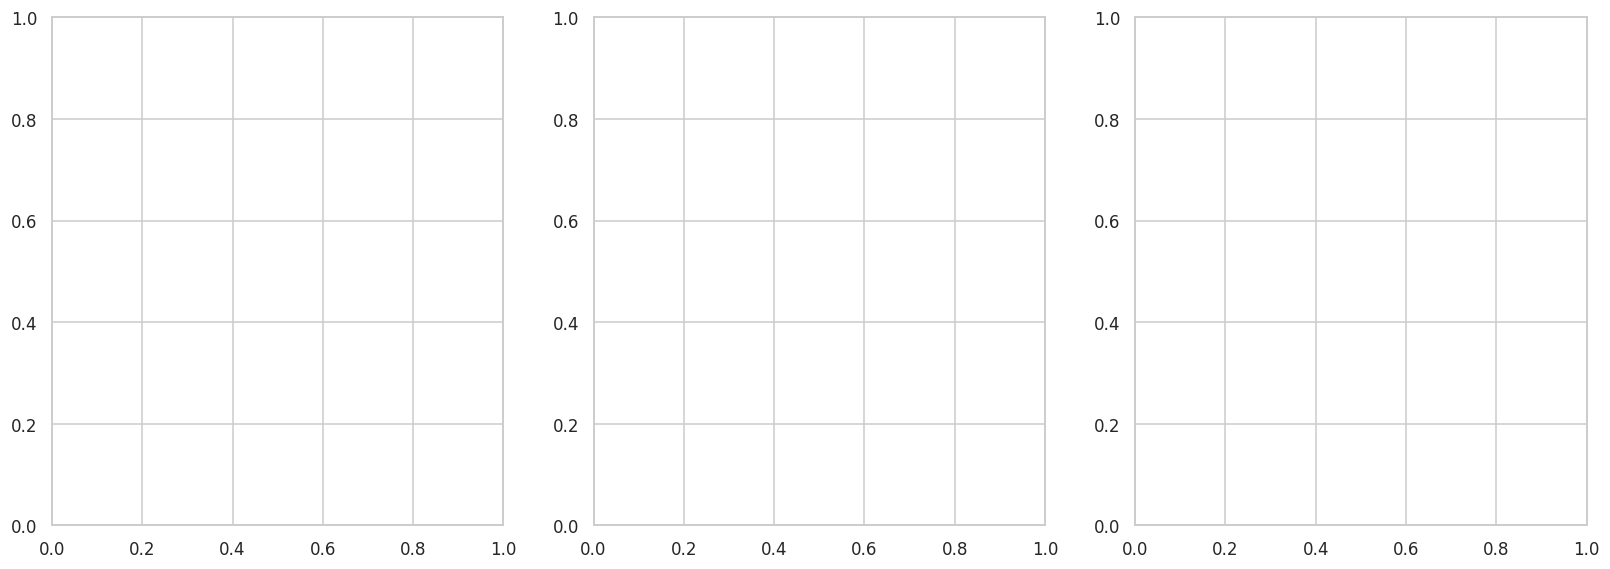

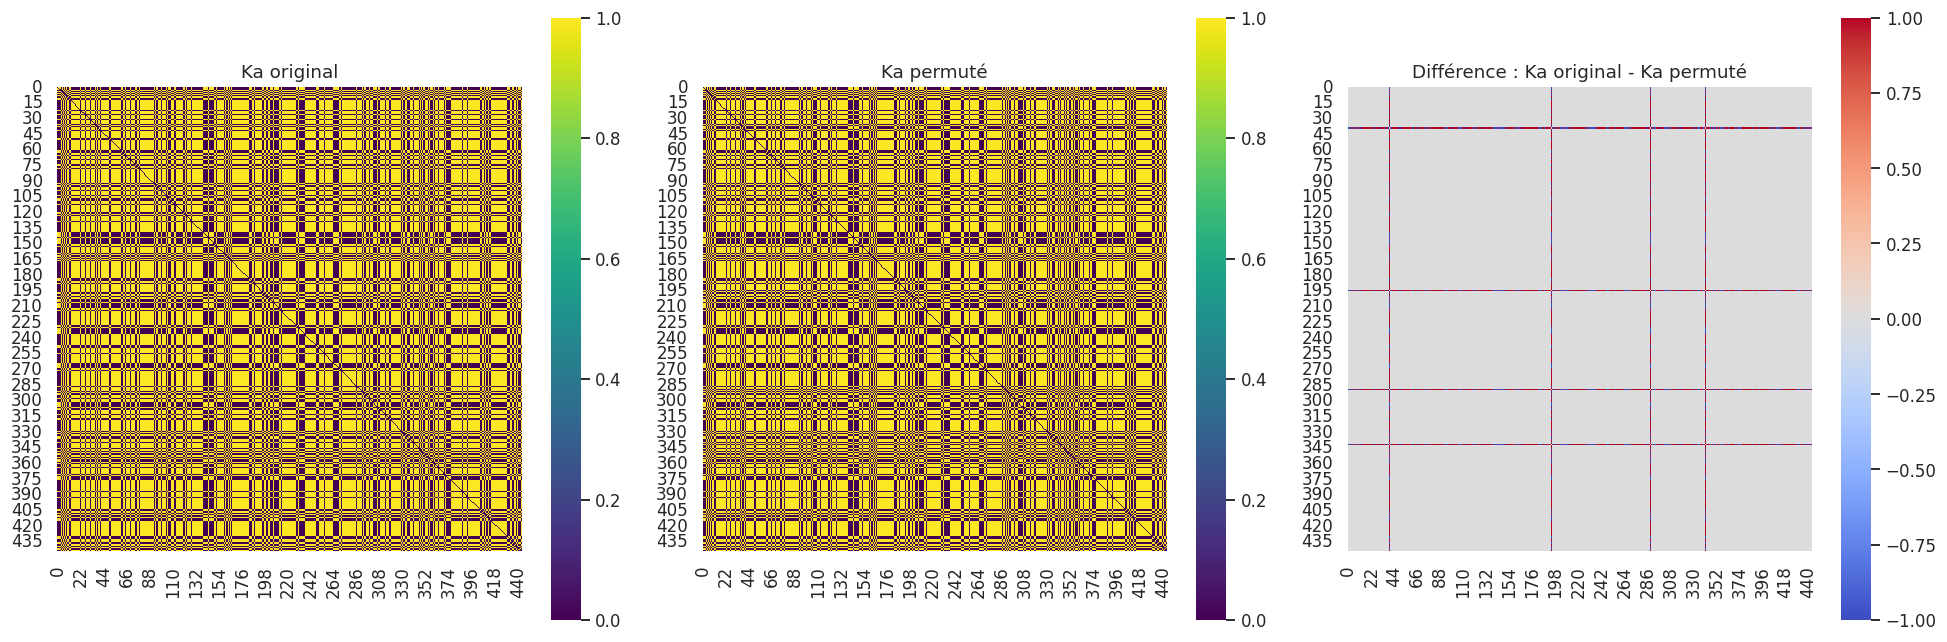

Nombre de cellules différentes : 3520 / 197136
Différence absolue moyenne : 0.0179
Différence absolue maximale : 1.0000


<Figure size 704x528 with 0 Axes>

Nombre de cellules différentes : 3520 / 197136
Différence absolue moyenne : 0.0179
Différence absolue maximale : 1.0000


In [37]:
# Différence signée : valeurs positives/négatives indiquent le sens du changement
difference = Ka - permuted_matrices_1pct["Ka"]

# Échelle commune pour comparer les deux matrices d'adjacence
vmin = min(Ka.min().min(), permuted_matrices_1pct["Ka"].min().min())
vmax = max(Ka.max().max(), permuted_matrices_1pct["Ka"].max().max())

# Échelle symétrique autour de 0 pour la différence
limite_diff = np.abs(difference).max()
if limite_diff == 0:
    limite_diff = 1
if limite_diff == 0:
    limite_diff = 1

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

original_ka = original_matrices["Ka"]
permuted_ka = permuted_matrices_1pct["Ka"]
difference = original_ka - permuted_ka

vmin = min(original_ka.min(), permuted_ka.min())
vmax = max(original_ka.max(), permuted_ka.max())

limite_diff = np.abs(difference).max() or 1

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.heatmap(original_ka, ax=axes[0], cmap="viridis",
            vmin=vmin, vmax=vmax, square=True)
axes[0].set_title("Ka original")

sns.heatmap(permuted_ka, ax=axes[1], cmap="viridis",
            vmin=vmin, vmax=vmax, square=True)
axes[1].set_title("Ka permuté")

sns.heatmap(difference, ax=axes[2], cmap="coolwarm",
            center=0, vmin=-limite_diff, vmax=limite_diff, square=True)
axes[2].set_title("Différence : Ka original - Ka permuté")

plt.tight_layout()
plt.show()

nb_differentes = np.count_nonzero(~np.isclose(difference, 0))
print(f"Nombre de cellules différentes : {nb_differentes} / {difference.size}")
print(f"Différence absolue moyenne : {np.abs(difference).mean():.4f}")
print(f"Différence absolue maximale : {np.abs(difference).max():.4f}")
axes[0].set_title("Ka")

sns.heatmap(
    permuted_matrices_1pct["Ka"],
    ax=axes[1],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    square=True
)
axes[1].set_title("Ka_permuted")

sns.heatmap(
    difference,
    ax=axes[2],
    cmap="coolwarm",
    center=0,
    vmin=-limite_diff,
    vmax=limite_diff,
    square=True
)
axes[2].set_title("Différence : Ka - Ka_permuted")

plt.tight_layout()
plt.show()

# Quelques mesures de différence
valeurs_diff = np.asarray(difference)
nb_differentes = np.count_nonzero(~np.isclose(valeurs_diff, 0))

print(f"Nombre de cellules différentes : {nb_differentes} / {valeurs_diff.size}")
print(f"Différence absolue moyenne : {np.abs(valeurs_diff).mean():.4f}")
print(f"Différence absolue maximale : {np.abs(valeurs_diff).max():.4f}")

In [24]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_1pct = mixed_bests_1pct["ICL_approx"]["model"]
node_clusters_1pct, view_components_1pct = best_model_1pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_1pct['ICL_approx']['K']}, {mixed_bests_1pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_1pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_1pct,
        "composante": view_components_1pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (7, 4)

Tailles des clusters d'individus (K):
0    108
1    188
2    101
3     26
4      4
5      4
6     13
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           0
1  Ks_original           1
2  Ka_permuted           2
3  Ks_permuted           3


### Test fonctions et modèle avec un bruit à 0% (aucune modification des descripteurs originaux)

In [25]:
original_matrices = load_adjacency_matrices(MATRIX_PATHS)
PERMUTATION_RATE = 0.00  # 0% de bruit
PERMUTATION_SEED = 42  # graine pour la permutation des labels

permuted_matrices_0pct = {
    name: permute_adjacency_labels(
        matrix,
        PERMUTATION_RATE,
        np.random.default_rng(PERMUTATION_SEED),
    )
    for name, matrix in original_matrices.items()
}

# Assembler les deux matrices originales et les deux matrices permutees
mixed_matrices_0pct = {
    "Ka_original": original_matrices["Ka"],
    "Ks_original": original_matrices["Ks"],
    "Ka_permuted": permuted_matrices_0pct["Ka"],
    "Ks_permuted": permuted_matrices_0pct["Ks"],
}

# build_tensor prend un seul dictionnaire de matrices
mixed_tensor_0pct, mixed_view_names_0pct = build_tensor(mixed_matrices_0pct)

print(f"Tenseur mimiSBM : shape={mixed_tensor_0pct.shape}")
print(f"Ordre des vues : {mixed_view_names_0pct}")

# Ajuster mimiSBM sur le tenseur a quatre vues
mixed_results_df_0pct, mixed_bests_0pct = grid_search(mixed_tensor_0pct)

# Resume du meilleur modele selon chaque critere
summary_0pct = pd.DataFrame([
    {
        "critere": criterion,
        "K": best["K"],
        "Q": best["Q"],
        "score": best["score"],
    }
    for criterion, best in mixed_bests_0pct.items()
])

display(summary_0pct)

Tenseur mimiSBM : shape=(444, 444, 4)
Ordre des vues : ['Ka_original', 'Ks_original', 'Ka_permuted', 'Ks_permuted']


,critere,K,Q,score
0,ILVB,6,2,-805.921098
1,ICL_variationnel,6,2,-805.921098
2,ICL_approx,6,2,-1092.387178


In [26]:
# voir les composantes et les clusters pour le meilleur modele selon ICL_approx
best_model_0pct = mixed_bests_0pct["ICL_approx"]["model"]
node_clusters_0pct, view_components_0pct = best_model_0pct.predict()

print(
    f"Critere utilise : ICL_approx  |  (K, Q) = "
    f"({mixed_bests_0pct['ICL_approx']['K']}, {mixed_bests_0pct['ICL_approx']['Q']})"
)

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters_0pct).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(
    pd.DataFrame({
        "vue": mixed_view_names_0pct,
        "composante": view_components_0pct
    })
)

Critere utilise : ICL_approx  |  (K, Q) = (6, 2)

Tailles des clusters d'individus (K):
0    191
1    108
2    102
3     26
4     13
5      4
Name: count, dtype: int64

Composante de vue retenue par vue:
           vue  composante
0  Ka_original           1
1  Ks_original           0
2  Ka_permuted           1
3  Ks_permuted           0
